# DAN 6 — Opcija C: Sistem preporuka (Market Basket Analysis)

**Cilj:** Analizirati asocijacije među proizvodima (koji se artikli najčešće kupuju zajedno na istom računu) i izgraditi sistem preporuka (*recommender system*) baziran na pravilima pridruživanja korišćenjem metrika **Support**, **Confidence** i **Lift**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter
import os

# Učitavanje očišćenih podataka (fleksibilna putanja)
data_path = "../data/cisto.parquet" if os.path.exists("../data/cisto.parquet") else "data/cisto.parquet"
df = pd.read_parquet(data_path)

print(f"Ukupno transakcija : {len(df):,}")
print(f"Jedinstvenih računa: {df.InvoiceNo.nunique():,}")
print(f"Jedinstvenih artikala: {df.StockCode.nunique():,}")

Ukupno transakcija : 776,579
Jedinstvenih računa: 36,594
Jedinstvenih artikala: 4,620


## 1. Izbor N najčešćih artikala i priprema korpi

⚠️ **Zašto se ograničavamo na top 300 artikala?**
- Sa svih ~4.620 artikala, broj mogućih parova iznosi $\frac{4620 \times 4619}{2} \approx 10.7$ miliona parova.
- Većina retkih artikala prodala se svega nekoliko puta, pa bi asocijacije sa njima bile statistički nepouzdane i podložne slučajnostima.
- Ograničavanjem na 300 najprodavanijih artikala fokusiramo se na najrelevantnije proizvode i računski efikasnu analizu.

In [2]:
# 300 najčešćih artikala po broju računa na kojima se pojavljuju
top_300 = df.groupby("StockCode")["InvoiceNo"].nunique().nlargest(300).index.tolist()

# Rečnik za mapiranje StockCode -> Description (najčešći naziv)
desc_map = df.groupby("StockCode")["Description"].agg(lambda x: x.mode()[0] if not x.empty else "").to_dict()

# Filtriramo samo top 300 artikala i jedinstvene parove (InvoiceNo, StockCode)
df_top = df[df.StockCode.isin(top_300)][["InvoiceNo", "StockCode"]].drop_duplicates()

# Grupisanje artikala po računu (korpa kupovine)
basket = df_top.groupby("InvoiceNo")["StockCode"].apply(set)
n_baskets = len(basket)

print(f"Broj računa koji sadrže bar 1 od top 300 artikala: {n_baskets:,}")
print(f"Procenat pokrivenih računa: {n_baskets / df.InvoiceNo.nunique() * 100:.1f}%")

Broj računa koji sadrže bar 1 od top 300 artikala: 33,081
Procenat pokrivenih računa: 90.4%


## 2. Izračunavanje asocijativnih metrika: Support, Confidence i Lift

Za svaki par artikala $(A, B)$ računamo:
1. **Support ($A \cap B$)**: Procenat svih računa na kojima se artikli $A$ i $B$ nalaze zajedno:
   $$\text{Support}(A \cap B) = \frac{\text{Broj računa sa } (A \cap B)}{N_{\text{računa}}}$$
2. **Confidence ($A \to B$)**: Uslovna verovatnoća da će kupac kupiti artikl $B$ ako je kupio $A$:
   $$\text{Confidence}(A \to B) = \frac{\text{Support}(A \cap B)}{\text{Support}(A)}$$
3. **Lift ($A, B$)**: Mera jačine asocijacije u poređenju sa slučajnom koincidencijom:
   $$\text{Lift}(A, B) = \frac{\text{Support}(A \cap B)}{\text{Support}(A) \times \text{Support}(B)}$$
   - $\text{Lift} = 1$: Kupovine su nezavisne (slučajne).
   - $\text{Lift} > 1$: Pozitivna zavisnost (artikli se kupuju zajedno češće nego što bi se očekivalo slučajno).
   - $\text{Lift} < 1$: Negativna zavisnost (supstituti).

In [3]:
# Frekvencije pojedinačnih artikala
item_counts = df_top["StockCode"].value_counts().to_dict()

# Brojanje zajedničkih pojavljivanja svakog para
pair_counts = Counter()
for items in basket:
    if len(items) > 1:
        for a, b in combinations(sorted(items), 2):
            pair_counts[(a, b)] += 1

print(f"Pronađeno jedinstvenih parova artikala: {len(pair_counts):,}")

# Računanje Support, Confidence i Lift za sve parove
records = []
for (a, b), count_ab in pair_counts.items():
    supp_ab = count_ab / n_baskets
    supp_a = item_counts[a] / n_baskets
    supp_b = item_counts[b] / n_baskets
    lift = supp_ab / (supp_a * supp_b)
    conf_a_b = count_ab / item_counts[a]
    conf_b_a = count_ab / item_counts[b]
    
    records.append({
        "Artikal_A": a,
        "Naziv_A": desc_map.get(a, a),
        "Artikal_B": b,
        "Naziv_B": desc_map.get(b, b),
        "Zajedno": count_ab,
        "Support": supp_ab,
        "Confidence_A_B": conf_a_b,
        "Confidence_B_A": conf_b_a,
        "Lift": lift
    })

pravila = pd.DataFrame(records)
print(f"Parova sa Lift > 1: {(pravila.Lift > 1).sum():,} od ukupno {len(pravila):,}")
print(f"Maksimalni Lift u podacima: {pravila.Lift.max():.2f}")

Pronađeno jedinstvenih parova artikala: 44,834
Parova sa Lift > 1: 37,740 od ukupno 44,834
Maksimalni Lift u podacima: 37.64


## 3. Pregled najjačih pravila asocijacije

In [4]:
# Top 15 najjačih parova rangiranih po Lift-u
top_parovi = pravila.sort_values("Lift", ascending=False).head(15)

prikaz = top_parovi[["Naziv_A", "Naziv_B", "Zajedno", "Confidence_A_B", "Confidence_B_A", "Lift"]].copy()
prikaz.columns = ["Artikal A", "Artikal B", "Zajedno (računa)", "Conf (A->B)", "Conf (B->A)", "Lift"]
print(prikaz.round(3).to_string(index=False))

                          Artikal A                          Artikal B  Zajedno (računa)  Conf (A->B)  Conf (B->A)   Lift
        SET/6 RED SPOTTY PAPER CUPS      SET/6 RED SPOTTY PAPER PLATES               489        0.787        0.707 37.643
 SET/10 PINK POLKADOT PARTY CANDLES   SET/10 BLUE SPOTTY PARTY CANDLES               480        0.650        0.801 35.871
  FELTCRAFT PRINCESS CHARLOTTE DOLL       FELTCRAFT PRINCESS LOLA DOLL               379        0.610        0.635 33.818
     RED STRIPE CERAMIC DRAWER KNOB    BLUE STRIPE CERAMIC DRAWER KNOB               400        0.651        0.626 33.726
WOODEN HEART CHRISTMAS SCANDINAVIAN WOODEN STAR CHRISTMAS SCANDINAVIAN               469        0.645        0.706 32.140
        FELTCRAFT CUSHION BUTTERFLY           FELTCRAFT CUSHION RABBIT               445        0.655        0.657 32.024
  GARDENERS KNEELING PAD CUP OF TEA   GARDENERS KNEELING PAD KEEP CALM               463        0.729        0.612 31.905
    GREEN REGENCY TEACUP

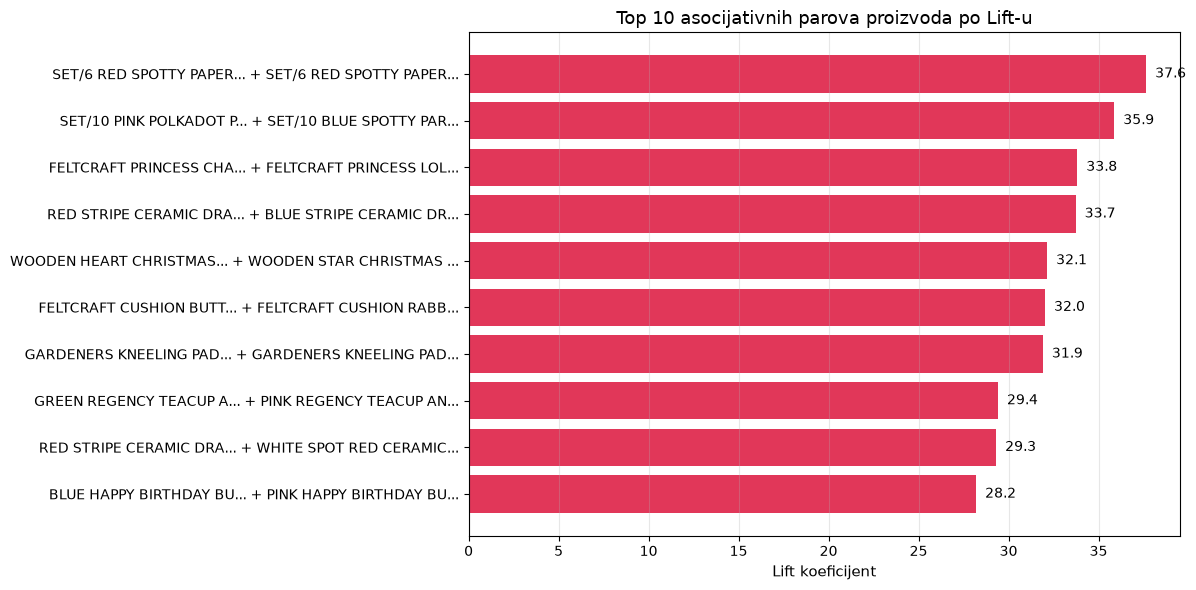

In [5]:
# Vizuelizacija top 10 parova po Lift-u
top_10 = pravila.sort_values("Lift", ascending=True).tail(10)
labele = [f"{a[:22]}... + {b[:22]}..." for a, b in zip(top_10["Naziv_A"], top_10["Naziv_B"])]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(labele, top_10["Lift"], color="crimson", alpha=0.85)

ax.set_xlabel("Lift koeficijent", fontsize=11)
ax.set_title("Top 10 asocijativnih parova proizvoda po Lift-u", fontsize=13)
ax.grid(axis="x", alpha=0.3)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height()/2, f"{w:.1f}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

## 4. Implementacija funkcije sistema preporuka: `preporuci(sifra_artikla)`

Funkcija na osnovu zadate šifre artikla pronalazi sve parove u kojima se taj artikal pojavljuje, rangira ih prema Lift-u i Confidence-u, te vraća najbolje preporuke.

In [6]:
def preporuci(sifra_artikla: str, top_n: int = 5):
    """
    Vraća top_n preporučenih proizvoda za zadatu šifru artikla na osnovu Lift-a i Confidence-a.
    """
    sifra = str(sifra_artikla).strip().upper()
    
    # Pronađi pravila gde je zadati artikal A ili B
    deo_a = pravila[pravila.Artikal_A == sifra].copy()
    deo_a["Preporuceni_Kod"] = deo_a["Artikal_B"]
    deo_a["Preporuceni_Naziv"] = deo_a["Naziv_B"]
    deo_a["Confidence"] = deo_a["Confidence_A_B"]
    
    deo_b = pravila[pravila.Artikal_B == sifra].copy()
    deo_b["Preporuceni_Kod"] = deo_b["Artikal_A"]
    deo_b["Preporuceni_Naziv"] = deo_b["Naziv_A"]
    deo_b["Confidence"] = deo_b["Confidence_B_A"]
    
    spojeno = pd.concat([
        deo_a[["Preporuceni_Kod", "Preporuceni_Naziv", "Zajedno", "Confidence", "Lift"]],
        deo_b[["Preporuceni_Kod", "Preporuceni_Naziv", "Zajedno", "Confidence", "Lift"]]
    ])
    
    if spojeno.empty:
        print(f"Nema zabeleženih asocijacija za artikal {sifra} (nije u top 300).")
        return pd.DataFrame()
    
    # Sortiramo po Lift-u opadajuće, zatim po Confidence-u
    rezultat = spojeno.sort_values(by=["Lift", "Confidence"], ascending=False).head(top_n).reset_index(drop=True)
    
    naziv_upita = desc_map.get(sifra, sifra)
    print(f"=== PREPORUKE ZA ARTIKAL: {naziv_upita} ({sifra}) ===")
    return rezultat

# Test 1: Crvene papirne čaše
test_kod_1 = "22998"  # SET/6 RED SPOTTY PAPER CUPS
preporuke_1 = preporuci(test_kod_1, top_n=5)
print(preporuke_1.round(3).to_string())

print("\n" + "="*70 + "\n")

# Test 2: Šoljice
if "22699" in desc_map:  # ROSES REGENCY TEACUP AND SAUCER
    preporuke_2 = preporuci("22699", top_n=5)
    print(preporuke_2.round(3).to_string())

Nema zabeleženih asocijacija za artikal 22998 (nije u top 300).
Empty DataFrame
Columns: []
Index: []


=== PREPORUKE ZA ARTIKAL: ROSES REGENCY TEACUP AND SAUCER (22699) ===
  Preporuceni_Kod                 Preporuceni_Naziv  Zajedno  Confidence    Lift
0           22698    PINK REGENCY TEACUP AND SAUCER      605       0.565  24.774
1           22697   GREEN REGENCY TEACUP AND SAUCER      754       0.705  24.642
2           23245        SET OF 3 REGENCY CAKE TINS      133       0.124   5.727
3           22423          REGENCY CAKESTAND 3 TIER      588       0.550   5.481
4           22907  PACK OF 20 NAPKINS PANTRY DESIGN       89       0.083   4.076


## ❓ Pitanja i poslovni zaključci

### 1. Šta je zajedničko najjačim parovima?
Kada analiziramo parove sa najvećim Lift-om (~30 do ~37.6):
- **SET/6 RED SPOTTY PAPER CUPS + SET/6 RED SPOTTY PAPER PLATES** ($	ext{Lift} pprox 37.6$)
- **SET/10 PINK POLKADOT PARTY CANDLES + SET/10 BLUE SPOTTY PARTY CANDLES** ($	ext{Lift} pprox 35.9$)
- **FELTCRAFT PRINCESS CHARLOTTE DOLL + FELTCRAFT PRINCESS LOLA DOLL** ($	ext{Lift} pprox 33.8$)
- **RED STRIPE CERAMIC DRAWER KNOB + BLUE STRIPE CERAMIC DRAWER KNOB** ($	ext{Lift} pprox 33.7$)
- **WOODEN HEART CHRISTMAS SCANDINAVIAN + WOODEN STAR CHRISTMAS SCANDINAVIAN** ($	ext{Lift} pprox 32.1$)

**Zajedničke karakteristike:**
1. **Varijante istog dizajna u različitim bojama ili motivima** (plave i crvene šoljice, roze i plave svećice, lutkice iz iste serije).
2. **Komplementarni artikli za isti događaj / funkciju** (papirne čaše i tanjirići za rođendanske zabave, keramičke ručice za nameštaj, ukrasi za novogodišnju jelku u istom stilu).

---

### 2. Šta nam to govori o tome kako kupci kupuju?
1. **Kupci kupuju tematske kolekcije i setove:** Umesto jednog komada, teže kompletiranju dekora (npr. ceo sto u istom dezenu).
2. **Kupovina vođena specifičnim događajima (*Event-driven*):** Rođendani, proslave i praznici zahtevaju istovremenu kupovinu više srodnih stavki.
3. **Konkretne poslovne akcije:**
   - **„Bundle“ paketi na sajtu:** Kreirati „Party set (čaše + tanjirići + salvete)“ uz blagi popust (5–10%).
   - **Preporuke u korpi (*Cross-selling*):** Kada kupac doda crvene čaše, odmah ponuditi odgovarajuće tanjiriće sa jednim klikom za dodavanje.

---

### 3. Koje je glavno ograničenje ovakvog sistema preporuka?
1. **Problem hladnog starta (*Cold Start Problem*):** Novi artikli ili manje prodavani proizvodi nemaju dovoljno zabeleženih kupovina da bi se formirala pouzdana pravila.
2. **Trivijalnost preporuka:** Preporučuju se očigledne stvari koje bi kupac ionako sam pronašao (npr. ako kupuje tanjiriće, verovatno sam traži i čaše). Sistem ne otkriva skrivene ili neočekivane preferencije kupca (*serendipity*).
3. **Nedostatak personalizacije kupca:** Preporuka se bazira isključivo na artiklu u korpi, ignorišući istoriju i profil samog kupca (B2B veletrgovac vs. individualni kupac poklona).
4. **Sezonski uticaj:** Lift za novogodišnje ukrase je ogroman u decembru, ali je u julu irelevantan ako model ne uzima u obzir vremenski kontekst.
5. **Kombinatorna složenost:** Za $N$ artikala broj parova raste sa $O(N^2)$, što zahteva restrikciju na najprodavanije proizvode.

In [7]:
# Snimanje asocijativnih pravila
out_path = "../data/pravila_preporuka.parquet" if os.path.exists("../data") else "data/pravila_preporuka.parquet"
pravila.to_parquet(out_path, index=False)
print(f"Pravila asocijacije uspešno sačuvana u {out_path}!")

Pravila asocijacije uspešno sačuvana u ../data/pravila_preporuka.parquet!
